## Supplied-data update — 4 November 2026
This notebook retains its previously executed analysis and source-access record. The subsequently uploaded BSOS CSV and codebooks are now analysed separately in **06_BSOS_Anxiety_Measurement.ipynb** and Appendix J. Earlier statements that BSOS data or empirical GAD-7 scores were unavailable are historical, not the current project status. The new file still lacks personalisation, comparison and digital-literacy variables. It is not merged with this notebook’s respondents.

# The Impact of Perceived Social Media Algorithm Personalisation on Anxiety Levels Among Generation Z: The Mediating Role of Social Comparison

## Notebook 02 Secondary analysis of social comparison and worry
David Thulani Tinotenda Dingani · ST10358804 · RPDA8412

This is the reproducibility notebook for the executed **secondary-only** study. It uses the same Ahmed dataset named in the approved proposal. It does not administer a survey, collect new participant data, or create synthetic research observations.

**Scope:** item-level comparison and worry, not GAD-7, clinical diagnosis, measured algorithm personalisation, mediation, or a South African population estimate. The original H1–H3 remain untested because required measurements are absent.

Open in Google Colab using **File → Upload notebook**, then **Runtime → Run all**. A CPU runtime is sufficient. Run the dependency cell first; if Colab asks for a restart after installation, restart and run all again. The supplied outputs were executed in a Python runtime, not in a signed-in Colab session. Rerun in Colab to create your own execution record.

The approved topic, questions and objectives remain unchanged. This notebook is a supporting secondary analysis; its measured outcomes do not replace anxiety in the research topic. See Section 1.4 and Table 4.7 of the report for the original questions and their evidential status.


## Environment and source
The reference run used Python 3.12.14. The analysis is exploratory, not preregistered. All source records and the four analytical specifications are fixed before model tuning.

In [1]:
# Reproducible package versions used for the report.
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError
required = {"numpy":"2.3.5", "pandas":"2.2.3", "scipy":"1.17.0",
            "scikit-learn":"1.8.0", "statsmodels":"0.15.0"}
missing=[]
for package, wanted in required.items():
    try:
        if version(package) != wanted: missing.append(f"{package}=={wanted}")
    except PackageNotFoundError:
        missing.append(f"{package}=={wanted}")
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
print("Package checks complete. Recorded report environment:", required)


Package checks complete. Recorded report environment: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'statsmodels': '0.15.0'}


In [2]:
from pathlib import Path
import hashlib, urllib.request, zipfile, io, json
ROOT = Path("/content/research_project") if Path("/content").exists() else Path.cwd()
(ROOT/"data").mkdir(parents=True,exist_ok=True)
DATA = ROOT/"data"/"smmh.csv"
EXPECTED_SHA256 = "fd7943ecf6e9b8dbaf678556a7e9413d26509b9e9be99b59406a64a482bd3d52"
SOURCE = "https://www.kaggle.com/datasets/souvikahmed071/social-media-and-mental-health"
DOWNLOAD = "https://www.kaggle.com/api/v1/datasets/download/souvikahmed071/social-media-and-mental-health?datasetVersionNumber=15"
if not DATA.exists():
    try:
        with urllib.request.urlopen(DOWNLOAD,timeout=60) as response:
            archive=zipfile.ZipFile(io.BytesIO(response.read()))
        if "smmh.csv" not in archive.namelist():
            raise ValueError("Expected source filename missing; inspect the original dataset version.")
        DATA.write_bytes(archive.read("smmh.csv"))
    except Exception as error:
        raise RuntimeError("Download failed. Download smmh.csv from the original source and upload it into /content/research_project/data/ in Colab, then rerun. Do not substitute another dataset.") from error
digest=hashlib.sha256(DATA.read_bytes()).hexdigest()
assert digest == EXPECTED_SHA256, "Source bytes differ from the report. Stop and audit the version before interpreting new results."
print("Verified source:",SOURCE)
print("SHA-256:",digest)


Verified source: https://www.kaggle.com/datasets/souvikahmed071/social-media-and-mental-health
SHA-256: fd7943ecf6e9b8dbaf678556a7e9413d26509b9e9be99b59406a64a482bd3d52


## Audit and deterministic preparation
Exclude minors and cohort-ambiguous older ages in the main sample. Preserve the proposal age range as sensitivity. Do not infer country from platform names.

In [3]:
from pathlib import Path
import json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr, chi2
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, balanced_accuracy_score, accuracy_score, f1_score, confusion_matrix, roc_curve
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SEED=8412
# ROOT and verified DATA were set by the acquisition cell above.
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)
raw=pd.read_csv(ROOT/'data'/'smmh.csv')
names=['timestamp','age','gender','relationship','occupation','affiliation','uses_social','platforms','time_category','purposeless','distraction_social','restlessness','distractibility','worry','concentration','comparison','comparison_feeling','validation','low_mood','interest_fluctuation','sleep']
assert len(raw.columns)==len(names)
d=raw.copy(); d.columns=names
original_cols=dict(zip(names,raw.columns))
d['row_id']=np.arange(len(d))
time_order=['Less than an Hour','Between 1 and 2 hours','Between 2 and 3 hours','Between 3 and 4 hours','Between 4 and 5 hours','More than 5 hours']
assert set(d.time_category)<=set(time_order)
d['time_code']=d.time_category.map(dict(zip(time_order,range(6))))
d['gender_group']=d.gender.str.strip().map({'Female':'Female','Male':'Male'}).fillna('Another or unspecified response')
d['student']=d.occupation.isin(['University Student','School Student']).astype(int)
for p in ['TikTok','Instagram','YouTube']:
    d[p]=d.platforms.str.split(',').apply(lambda v:int(p in [x.strip() for x in v]))
platform_ok=d[['TikTok','Instagram','YouTube']].sum(axis=1)>0
active=d.uses_social.eq('Yes')
integer_age=d.age.eq(np.floor(d.age))
eligible=d.age.between(18,24)&integer_age&active&platform_ok
main=d.loc[eligible].copy()
assert main[['worry','comparison']].isin(range(1,6)).all().all()
main['high_worry']=(main.worry>=4).astype(int)
BASE=['age','gender_group','time_category','student','TikTok','Instagram','YouTube']
PLUS=BASE+['comparison']
audit={'raw_n':len(raw),'raw_columns':len(raw.columns),'duplicates_full':int(raw.duplicated().sum()),'duplicates_excluding_timestamp':int(raw.drop(columns=raw.columns[0]).duplicated().sum()),'missing_by_column':raw.isna().sum().to_dict(),'age_min':float(d.age.min()),'age_max':float(d.age.max()),'fractional_age_count':int((~integer_age).sum()),'main_n':len(main),'main_class_counts':main.high_worry.value_counts().sort_index().to_dict(),'main_gender_counts':main.gender_group.value_counts().to_dict(),'main_occupation_counts':main.occupation.value_counts().to_dict(),'main_time_counts':main.time_category.value_counts().to_dict(),'main_platform_counts':main[['TikTok','Instagram','YouTube']].sum().to_dict(),'main_age_mean':float(main.age.mean()),'main_age_sd':float(main.age.std()),'main_worry_counts':main.worry.value_counts().sort_index().to_dict(),'main_comparison_counts':main.comparison.value_counts().sort_index().to_dict(),'sha256_csv':hashlib.sha256((ROOT/'data'/'smmh.csv').read_bytes()).hexdigest(),'flow':{'start':len(d),'age_18_24_integer':int((d.age.between(18,24)&integer_age).sum()),'then_active':int((d.age.between(18,24)&integer_age&active).sum()),'then_platforms':int(eligible.sum())},'timestamp_years':d.timestamp.str.extract(r'/(\d{4})')[0].value_counts().to_dict()}



## Ordinal association and uncertainty
Use the original five ordered categories. The bootstrap quantifies record-level uncertainty; it does not establish population representativeness.

In [4]:
# A single ordinal item is not a scale; no internal consistency coefficient is computed.
rng=np.random.default_rng(SEED)
rho,p=spearmanr(main.comparison,main.worry)
boot=[]
for _ in range(5000):
    j=rng.integers(0,len(main),len(main));q=main.iloc[j]
    boot.append(spearmanr(q.comparison,q.worry).statistic)
assoc={'spearman_rho':float(rho),'spearman_p':float(p),'bootstrap95':np.quantile(boot,[.025,.975]).tolist()}

def design(q, categorical_comparison=False):
    x=q[['age','time_code','student','TikTok','Instagram','YouTube']].astype(float).copy()
    # Time is categorical in the inferential analysis, avoiding equal-hour assumptions.
    times=pd.Series(pd.Categorical(q.time_code,categories=[5,0,1,2,3,4]),index=q.index)
    genders=pd.Series(pd.Categorical(q.gender_group,categories=['Female','Male','Another or unspecified response']),index=q.index)
    x=x.drop(columns='time_code').join(pd.get_dummies(times,prefix='time',drop_first=True,dtype=float))
    x=x.join(pd.get_dummies(genders,prefix='gender',drop_first=True,dtype=float))
    if categorical_comparison:
        x=x.join(pd.get_dummies(q.comparison,prefix='comparison',drop_first=True,dtype=float))
    else: x['comparison']=q.comparison.astype(float)
    return x.loc[:,x.nunique()>1]

x=design(main)
ordfit=OrderedModel(main.worry.astype(int),x,distr='logit').fit(method='bfgs',disp=False,maxiter=2000)
ci=ordfit.conf_int()
ordinal=pd.DataFrame({'term':ordfit.params.index,'estimate':ordfit.params.values,'se':ordfit.bse.values,'p':ordfit.pvalues.values,'ci_low':ci.iloc[:,0].values,'ci_high':ci.iloc[:,1].values})
ordinal.to_csv(OUT/'ordinal_coefficients.csv',index=False)
assoc.update({'ordinal_comparison_or':float(np.exp(ordfit.params['comparison'])),'ordinal_comparison_or95':np.exp(ci.loc['comparison'].values).tolist(),'ordinal_comparison_p':float(ordfit.pvalues['comparison']),'ordinal_converged':bool(ordfit.mle_retvals['converged']),'ordinal_condition_number':float(np.linalg.cond(x))})
catfit=OrderedModel(main.worry.astype(int),design(main,True),distr='logit').fit(method='bfgs',disp=False,maxiter=2000)
assoc['comparison_nonlinearity_lr']=float(2*(catfit.llf-ordfit.llf))
assoc['comparison_nonlinearity_df']=int(len(catfit.params)-len(ordfit.params))
assoc['comparison_nonlinearity_p']=float(chi2.sf(assoc['comparison_nonlinearity_lr'],assoc['comparison_nonlinearity_df']))
thresholds=[]
for cut in range(2,6):
    f=sm.GLM((main.worry>=cut).astype(int),sm.add_constant(x),family=sm.families.Binomial()).fit(cov_type='HC3')
    c=f.conf_int().loc['comparison']
    thresholds.append({'cutpoint':cut,'positive_n':int((main.worry>=cut).sum()),'comparison_or':float(np.exp(f.params['comparison'])),'ci_low':float(np.exp(c.iloc[0])),'ci_high':float(np.exp(c.iloc[1])),'p':float(f.pvalues['comparison'])})
pd.DataFrame(thresholds).to_csv(OUT/'threshold_sensitivity.csv',index=False)
from statsmodels.stats.outliers_influence import variance_inflation_factor
vx=sm.add_constant(x)
pd.DataFrame({'term':vx.columns,'vif':[variance_inflation_factor(vx.values,i) for i in range(vx.shape[1])]}).to_csv(OUT/'vif.csv',index=False)



## Sensitivity to eligibility
These overlapping subsets are sensitivity checks, not independent replications.

In [5]:
# Age and platform sensitivity analyses are separate, with no target redefinition.
sens=[]
for label,mask in [('main_18_24',eligible),('proposal_age_18_27',d.age.between(18,27)&integer_age&active&platform_ok),('all_adults',d.age.ge(18)&integer_age&active&platform_ok),('all_platforms_18_24',d.age.between(18,24)&integer_age&active)]:
    q=d[mask]; r,pp=spearmanr(q.comparison,q.worry)
    sens.append({'sample':label,'n':len(q),'rho':float(r),'p':float(pp)})
pd.DataFrame(sens).to_csv(OUT/'sample_sensitivity.csv',index=False)



## Prediction design and fitting
The fixed 75:25 split uses seed 8412. Tuning occurs only within development data. Pipelines keep transformations within each fold. The target is worry score 4 or 5, not anxiety diagnosis.

In [6]:
# Freeze a stratified 25% test set before any tuning or feature-importance inspection.
train_idx,test_idx=train_test_split(np.arange(len(main)),test_size=.25,random_state=SEED,stratify=main.high_worry)
train=main.iloc[train_idx].copy();test=main.iloc[test_idx].copy()
assert set(train.row_id).isdisjoint(set(test.row_id))
folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(train,train.high_worry))

def pipeline(cols,clf):
    cats=[c for c in ['gender_group','time_category'] if c in cols]
    nums=[c for c in cols if c not in cats]
    numeric=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    return Pipeline([('preprocess',ColumnTransformer([('numeric',numeric,nums),('categorical',categorical,cats)])),('model',clf)])

specs={
 'Dummy prevalence':(BASE,DummyClassifier(strategy='prior'),{}),
 'Logistic baseline':(BASE,LogisticRegression(max_iter=3000,random_state=SEED),{'model__C':[.1,1,10]}),
 'Logistic plus comparison':(PLUS,LogisticRegression(max_iter=3000,random_state=SEED),{'model__C':[.1,1,10]}),
 'Random Forest plus comparison':(PLUS,RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=1),{'model__max_depth':[3,None],'model__min_samples_leaf':[5,10]})
}
scores=[];predictions={};models={};cvrows=[];params={}
def metrics(y,pred):
    yh=pred>=.5
    cm=confusion_matrix(y,yh,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
    return {'roc_auc':roc_auc_score(y,pred),'average_precision':average_precision_score(y,pred),'brier':brier_score_loss(y,pred),'accuracy':accuracy_score(y,yh),'balanced_accuracy':balanced_accuracy_score(y,yh),'f1':f1_score(y,yh,zero_division=0),'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
for name,(cols,clf,grid) in specs.items():
    pipe=pipeline(cols,clf)
    if grid:
        search=GridSearchCV(pipe,grid,scoring='roc_auc',cv=folds,n_jobs=1,refit=True,return_train_score=False)
        search.fit(train[cols],train.high_worry)
        model=search.best_estimator_;params[name]=search.best_params_
        for k in range(len(search.cv_results_['params'])):
            cvrows.append({'model':name,'params':str(search.cv_results_['params'][k]),'mean_cv_auc':search.cv_results_['mean_test_score'][k],'sd_cv_auc':search.cv_results_['std_test_score'][k],'selected':k==search.best_index_})
    else:
        model=pipe.fit(train[cols],train.high_worry);params[name]={}
    prob=model.predict_proba(test[cols])[:,1]
    predictions[name]=prob;models[name]=model
    scores.append({'model':name,**metrics(test.high_worry,prob)})
    print(name,scores[-1],flush=True)
pd.DataFrame(scores).to_csv(OUT/'test_metrics.csv',index=False)
pd.DataFrame(cvrows).to_csv(OUT/'cv_results.csv',index=False)



Dummy prevalence {'model': 'Dummy prevalence', 'roc_auc': 0.5, 'average_precision': 0.6621621621621622, 'brier': 0.22376000004426944, 'accuracy': 0.6621621621621622, 'balanced_accuracy': 0.5, 'f1': 0.7967479674796748, 'sensitivity': np.float64(1.0), 'specificity': np.float64(0.0), 'tn': 0, 'fp': 25, 'fn': 0, 'tp': 49}
Logistic baseline {'model': 'Logistic baseline', 'roc_auc': 0.5518367346938775, 'average_precision': 0.6800970790122888, 'brier': 0.23185375031366587, 'accuracy': 0.6216216216216216, 'balanced_accuracy': 0.5085714285714286, 'f1': 0.75, 'sensitivity': np.float64(0.8571428571428571), 'specificity': np.float64(0.16), 'tn': 4, 'fp': 21, 'fn': 7, 'tp': 42}
Logistic plus comparison {'model': 'Logistic plus comparison', 'roc_auc': 0.6228571428571429, 'average_precision': 0.7608632146658564, 'brier': 0.217689575772013, 'accuracy': 0.6756756756756757, 'balanced_accuracy': 0.5787755102040817, 'f1': 0.7818181818181819, 'sensitivity': np.float64(0.8775510204081632), 'specificity': np

## Uncertainty and model interpretation
Paired stratified bootstrap intervals condition on the fitted models and observed class counts. Permutation importance is descriptive and is not used to retune models.

In [7]:
# Bootstrap the frozen held-out predictions, preserving paired comparisons.
byclass=[np.flatnonzero(test.high_worry.values==c) for c in [0,1]]
rng=np.random.default_rng(SEED+1);bs={name:[] for name in predictions};delta=[]
for _ in range(2000):
    idx=np.concatenate([rng.choice(ix,len(ix),replace=True) for ix in byclass]);y=test.high_worry.values[idx]
    for name,prob in predictions.items():
        bs[name].append([roc_auc_score(y,prob[idx]),brier_score_loss(y,prob[idx]),average_precision_score(y,prob[idx])])
    delta.append([roc_auc_score(y,predictions['Logistic plus comparison'][idx])-roc_auc_score(y,predictions['Logistic baseline'][idx]),brier_score_loss(y,predictions['Logistic plus comparison'][idx])-brier_score_loss(y,predictions['Logistic baseline'][idx])])
intervals=[]
for name,v in bs.items():
    for j,m in enumerate(['roc_auc','brier','average_precision']):
        lo,hi=np.quantile(np.array(v)[:,j],[.025,.975]);intervals.append({'model':name,'metric':m,'ci_low':float(lo),'ci_high':float(hi)})
pd.DataFrame(intervals).to_csv(OUT/'test_bootstrap_intervals.csv',index=False)
delta=np.array(delta)
ml={'seed':SEED,'train_n':len(train),'test_n':len(test),'train_positive':int(train.high_worry.sum()),'test_positive':int(test.high_worry.sum()),'params':params,'delta_auc95':np.quantile(delta[:,0],[.025,.975]).tolist(),'delta_brier95':np.quantile(delta[:,1],[.025,.975]).tolist()}
imp=permutation_importance(models['Logistic plus comparison'],test[PLUS],test.high_worry,scoring='roc_auc',n_repeats=30,random_state=SEED,n_jobs=1)
pd.DataFrame({'feature':PLUS,'mean_auc_drop':imp.importances_mean,'sd_auc_drop':imp.importances_std}).to_csv(OUT/'permutation_importance.csv',index=False)
# Keep row membership private locally for reproducibility, not in public result bundles.
pd.DataFrame({'row_id':main.row_id,'partition':np.where(np.isin(np.arange(len(main)),test_idx),'test','train')}).to_csv(OUT/'split_manifest_private.csv',index=False)



## Figures and export
Figures are generated from executed data. Raw records and individual predictions are not printed. A private split manifest remains local and is excluded from public bundles.

In [8]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'savefig.dpi':220})
table=pd.crosstab(main.comparison,main.worry).reindex(index=range(1,6),columns=range(1,6),fill_value=0)
table.to_csv(OUT/'comparison_worry_counts.csv')
fig,ax=plt.subplots(figsize=(7.4,4.9));im=ax.imshow(table.values,cmap='Blues')
for i in range(5):
 for j in range(5):ax.text(j,i,str(table.iloc[i,j]),ha='center',va='center',color='white' if table.iloc[i,j]>table.values.max()*.65 else 'black')
ax.set(xticks=range(5),xticklabels=range(1,6),yticks=range(5),yticklabels=range(1,6),xlabel='Worry item score',ylabel='Social comparison item score',title=f'Observed responses in the eligible sample (n = {len(main)})')
fig.colorbar(im,ax=ax,label='Number of records');fig.tight_layout();fig.savefig(FIG/'01_comparison_worry.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(7.4,4.7))
for name,prob in predictions.items():
 if name.startswith('Dummy'):continue
 fpr,tpr,_=roc_curve(test.high_worry,prob);ax.plot(fpr,tpr,label=f"{name}: {roc_auc_score(test.high_worry,prob):.3f}")
ax.plot([0,1],[0,1],'--',color='grey',label='Chance ranking')
ax.set(xlabel='False positive rate',ylabel='True positive rate',title=f'Held-out discrimination (n = {len(test)})');ax.legend(loc='lower right',fontsize=8);fig.tight_layout();fig.savefig(FIG/'02_roc.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(7.4,4.7))
for name in ['Logistic baseline','Logistic plus comparison','Random Forest plus comparison']:
 obs,prob=calibration_curve(test.high_worry,predictions[name],n_bins=4,strategy='quantile');ax.plot(prob,obs,'o-',label=name)
ax.plot([0,1],[0,1],'--',color='grey');ax.set(xlabel='Mean predicted probability',ylabel='Observed proportion with worry score 4 or 5',title='Descriptive calibration in four test-set bins',xlim=(0,1),ylim=(0,1));ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'03_calibration.png');plt.close(fig)
t=pd.DataFrame(thresholds);fig,ax=plt.subplots(figsize=(7.4,4.7))
ax.errorbar(t.comparison_or,t.cutpoint,xerr=[t.comparison_or-t.ci_low,t.ci_high-t.comparison_or],fmt='o',capsize=4,color='#235670');ax.axvline(1,color='grey',linestyle='--');ax.set(xlabel='Adjusted odds ratio per comparison score point (95% CI)',ylabel='Worry score threshold',yticks=range(2,6),title='Sensitivity to the definition of elevated worry');fig.tight_layout();fig.savefig(FIG/'04_threshold_sensitivity.png');plt.close(fig)

env={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'scikit_learn':sklearn.__version__,'statsmodels':sm.__version__}
result={'audit':audit,'association':assoc,'ml':ml,'environment':env}
(OUT/'summary.json').write_text(json.dumps(result,indent=2))
field_decisions = {
 'timestamp': ('Audit only', 'Extract collection year 2022; exclude from models', 'Not a participant key or repeated observation'),
 'age': ('Eligibility and predictor', 'Integer ages 18–24 main; numeric predictor; 18–27 and adults in sensitivity', 'No birthday or exact birth cohort'),
 'gender': ('Predictor', 'Female; Male; pooled another or unspecified response', 'Sparse pooled responses do not represent one identity'),
 'relationship': ('Excluded', 'No model transformation', 'Outside the fixed demographic and usage feature set'),
 'occupation': ('Predictor', 'University Student or School Student = 1; otherwise 0', 'Sparse non-student group; unusual responses retained'),
 'affiliation': ('Excluded', 'No model transformation', '30 missing values in source; no country inference'),
 'uses_social': ('Eligibility', 'Require Yes', 'Self-report rather than behavioural log'),
 'platforms': ('Eligibility and predictors', 'Split commas; exact TikTok, Instagram, YouTube indicators; require any', 'Non-exclusive membership, not recommendation exposure'),
 'time_category': ('Predictor', 'Six nominal dummy-coded duration bands', 'Open highest band; not exact hours'),
 'purposeless': ('Excluded', 'No model transformation', 'Not a validated gratification measure'),
 'distraction_social': ('Excluded', 'No model transformation', 'Would change the fixed comparison-information question'),
 'restlessness': ('Excluded', 'No model transformation', 'Symptom-adjacent item, not used to reconstruct worry'),
 'distractibility': ('Excluded', 'No model transformation', 'Symptom-adjacent item, not used to reconstruct worry'),
 'worry': ('Outcome', 'Ordinal 1–5; classification 4–5 = 1 and 1–3 = 0', 'Single item; not GAD-7, diagnosis or clinical cut-off'),
 'concentration': ('Excluded', 'No model transformation', 'Symptom-adjacent item, not used to reconstruct worry'),
 'comparison': ('Principal explanatory variable', 'Ordinal 1–5; numeric log-odds term; categorical sensitivity', 'Single comparison item, not the INCOM scale'),
 'comparison_feeling': ('Excluded', 'No model transformation', 'Direction of response anchors not sufficiently documented'),
 'validation': ('Excluded', 'No model transformation', 'Outside the fixed comparison-information question'),
 'low_mood': ('Excluded', 'No model transformation', 'Symptom-adjacent item, not used to reconstruct worry'),
 'interest_fluctuation': ('Excluded', 'No model transformation', 'Symptom-adjacent item, not used to reconstruct worry'),
 'sleep': ('Excluded', 'No model transformation', 'Symptom-adjacent item, not used to reconstruct worry')
}
pd.DataFrame([{'variable':k, 'source_column':v, 'role':field_decisions[k][0],
               'coding':field_decisions[k][1], 'limit':field_decisions[k][2]}
              for k,v in original_cols.items()]).to_csv(OUT/'source_dictionary.csv',index=False)
print(json.dumps(result,indent=2),flush=True)


{
  "audit": {
    "raw_n": 481,
    "raw_columns": 21,
    "duplicates_full": 0,
    "duplicates_excluding_timestamp": 0,
    "missing_by_column": {
      "Timestamp": 0,
      "1. What is your age?": 0,
      "2. Gender": 0,
      "3. Relationship Status": 0,
      "4. Occupation Status": 0,
      "5. What type of organizations are you affiliated with?": 30,
      "6. Do you use social media?": 0,
      "7. What social media platforms do you commonly use?": 0,
      "8. What is the average time you spend on social media every day?": 0,
      "9. How often do you find yourself using Social media without a specific purpose?": 0,
      "10. How often do you get distracted by Social media when you are busy doing something?": 0,
      "11. Do you feel restless if you haven't used Social media in a while?": 0,
      "12. On a scale of 1 to 5, how easily distracted are you?": 0,
      "13. On a scale of 1 to 5, how much are you bothered by worries?": 0,
      "14. Do you find it difficult t

## Inspect the numerical and visual evidence

test_metrics.csv
test_bootstrap_intervals.csv
sample_sensitivity.csv
threshold_sensitivity.csv


,model,roc_auc,average_precision,brier,accuracy,balanced_accuracy,f1,sensitivity,specificity,tn,fp,fn,tp
0,Dummy prevalence,0.5000,0.6622,0.2238,0.6622,0.5000,0.7967,1.0000,0.00,0,25,0,49
1,Logistic baseline,0.5518,0.6801,0.2319,0.6216,0.5086,0.7500,0.8571,0.16,4,21,7,42
2,Logistic plus comparison,0.6229,0.7609,0.2177,0.6757,0.5788,0.7818,0.8776,0.28,7,18,6,43
3,Random Forest plus comparison,0.6380,0.7547,0.2144,0.6486,0.4996,0.7833,0.9592,0.04,1,24,2,47


,model,metric,ci_low,ci_high
0,Dummy prevalence,roc_auc,0.5000,0.5000
1,Dummy prevalence,brier,0.2238,0.2238
2,Dummy prevalence,average_precision,0.6622,0.6622
3,Logistic baseline,roc_auc,0.4134,0.6939
4,Logistic baseline,brier,0.2053,0.2580
5,Logistic baseline,average_precision,0.6030,0.8041
6,Logistic plus comparison,roc_auc,0.4844,0.7649
7,Logistic plus comparison,brier,0.1814,0.2517
8,Logistic plus comparison,average_precision,0.6709,0.8620
9,Random Forest plus comparison,roc_auc,0.5033,0.7763


,sample,n,rho,p
0,main_18_24,295,0.3823,0.0
1,proposal_age_18_27,335,0.3833,0.0
2,all_adults,426,0.3916,0.0
3,all_platforms_18_24,308,0.3885,0.0


,cutpoint,positive_n,comparison_or,ci_low,ci_high,p
0,2,278,1.8233,1.0088,3.2955,0.0467
1,3,244,1.6323,1.2379,2.1523,0.0005
2,4,197,1.6304,1.3289,2.0001,0.0000
3,5,104,1.6866,1.3730,2.0718,0.0000


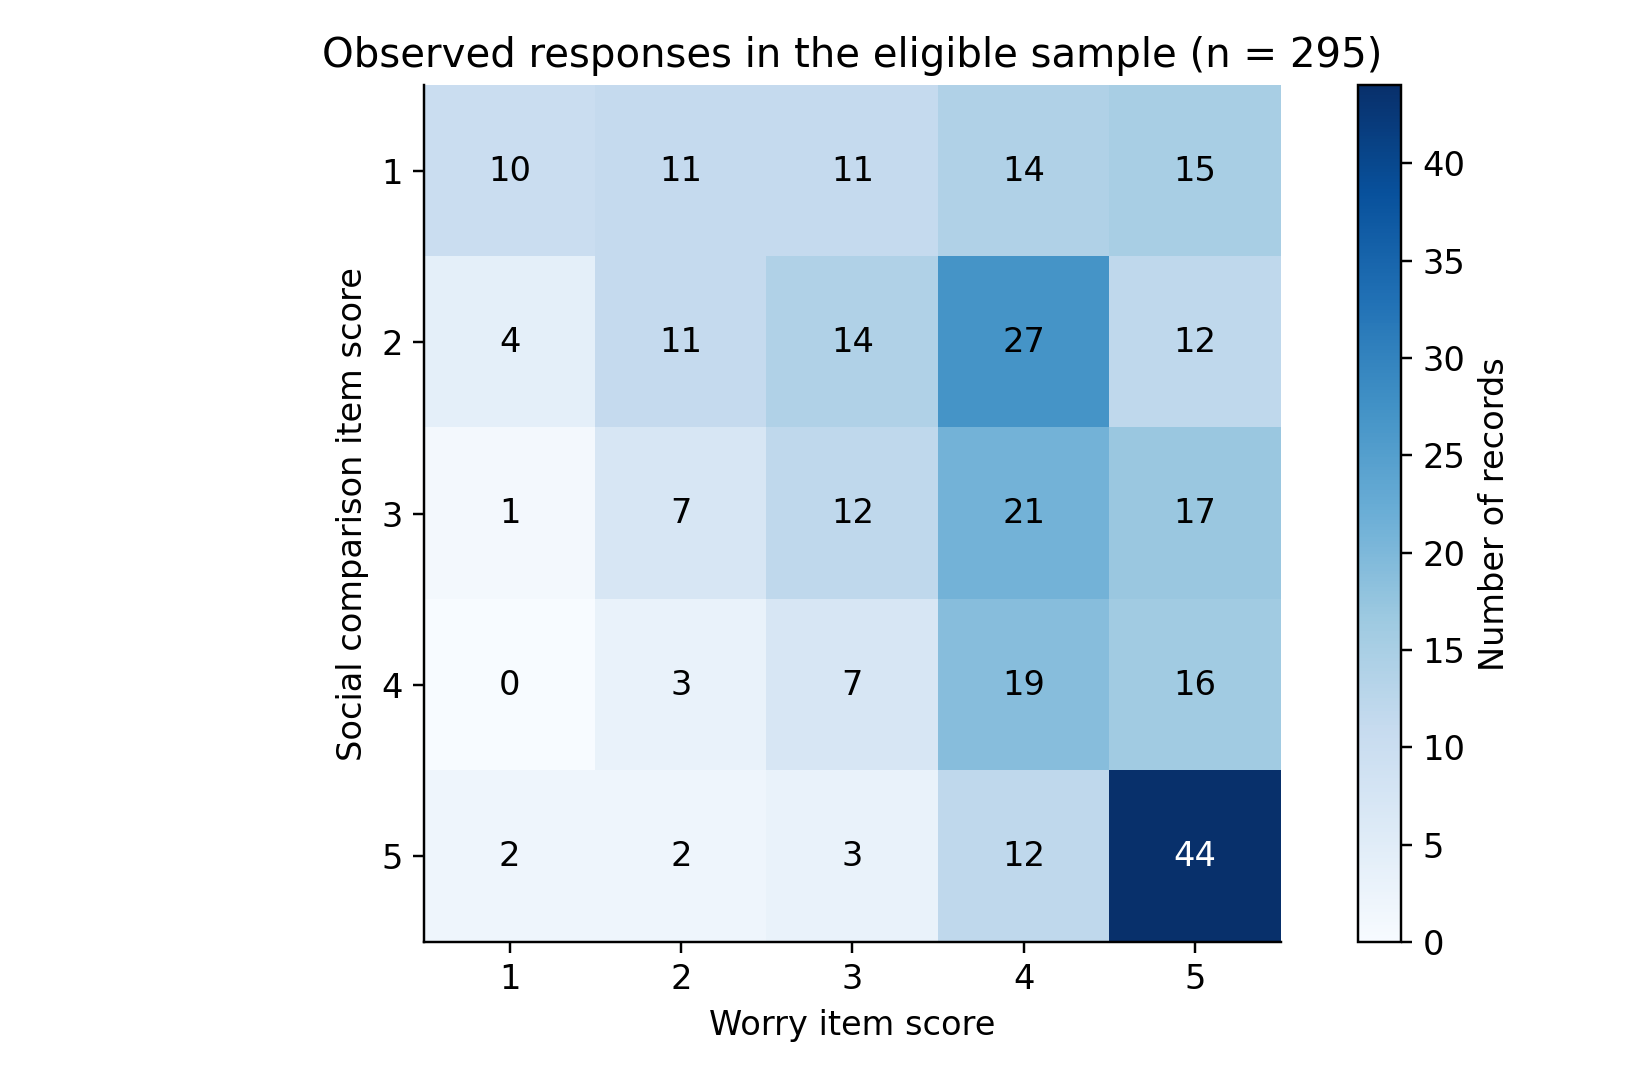

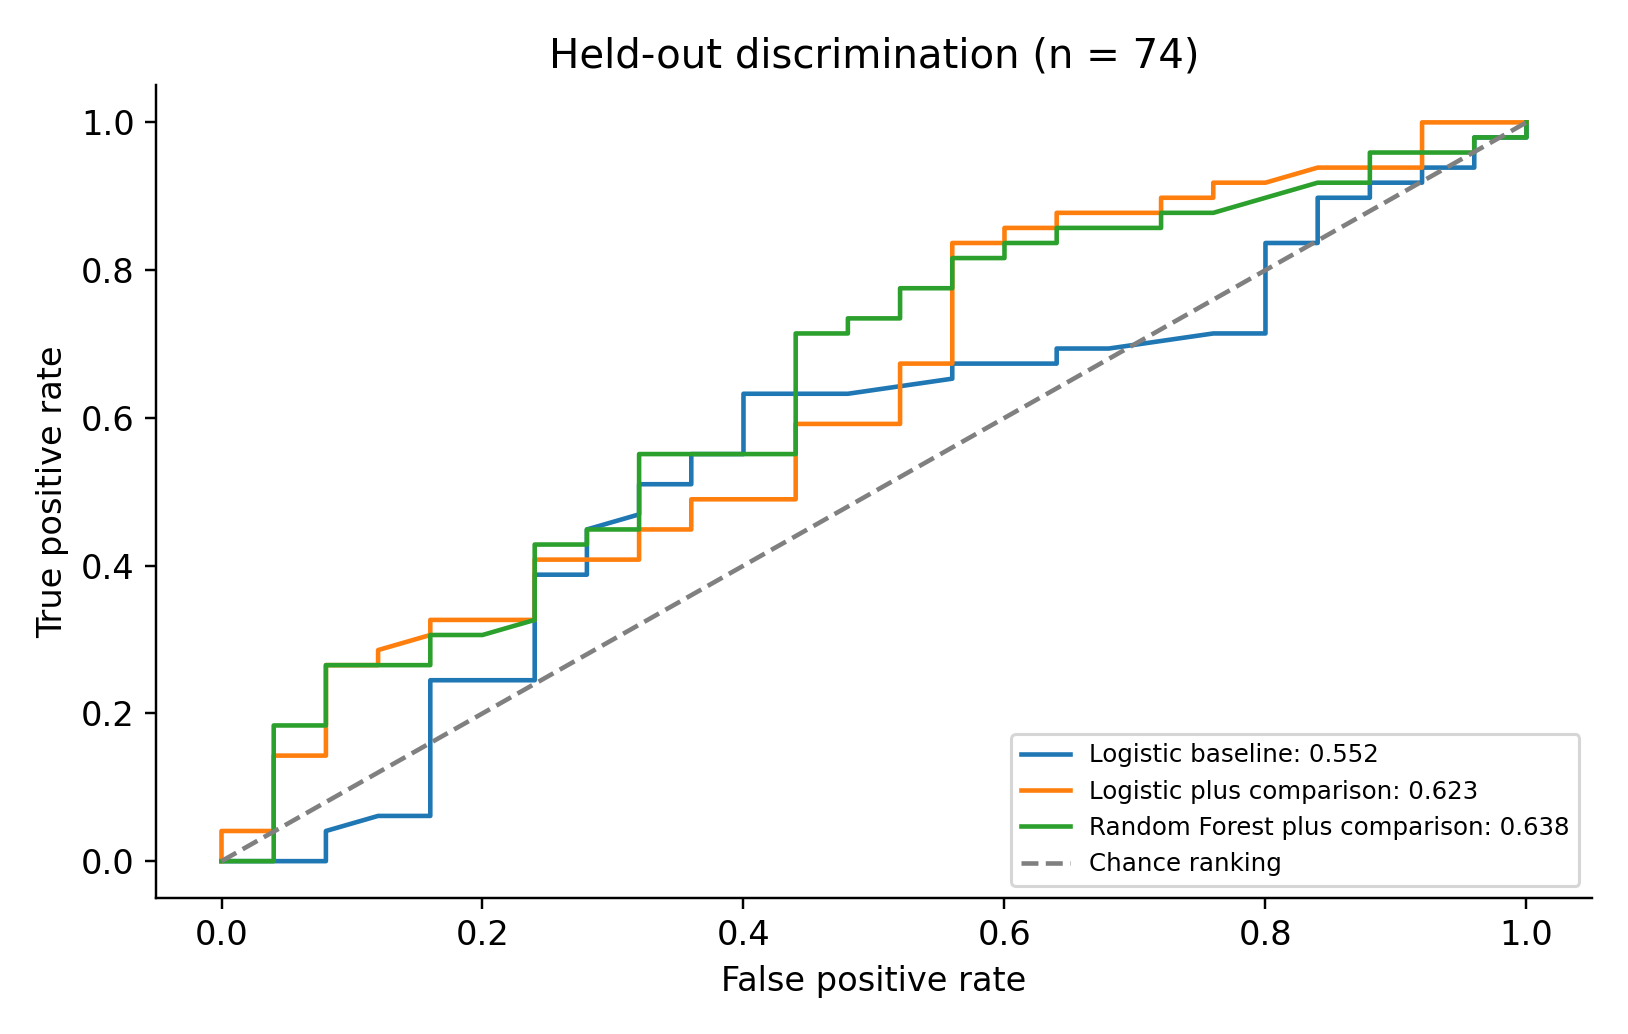

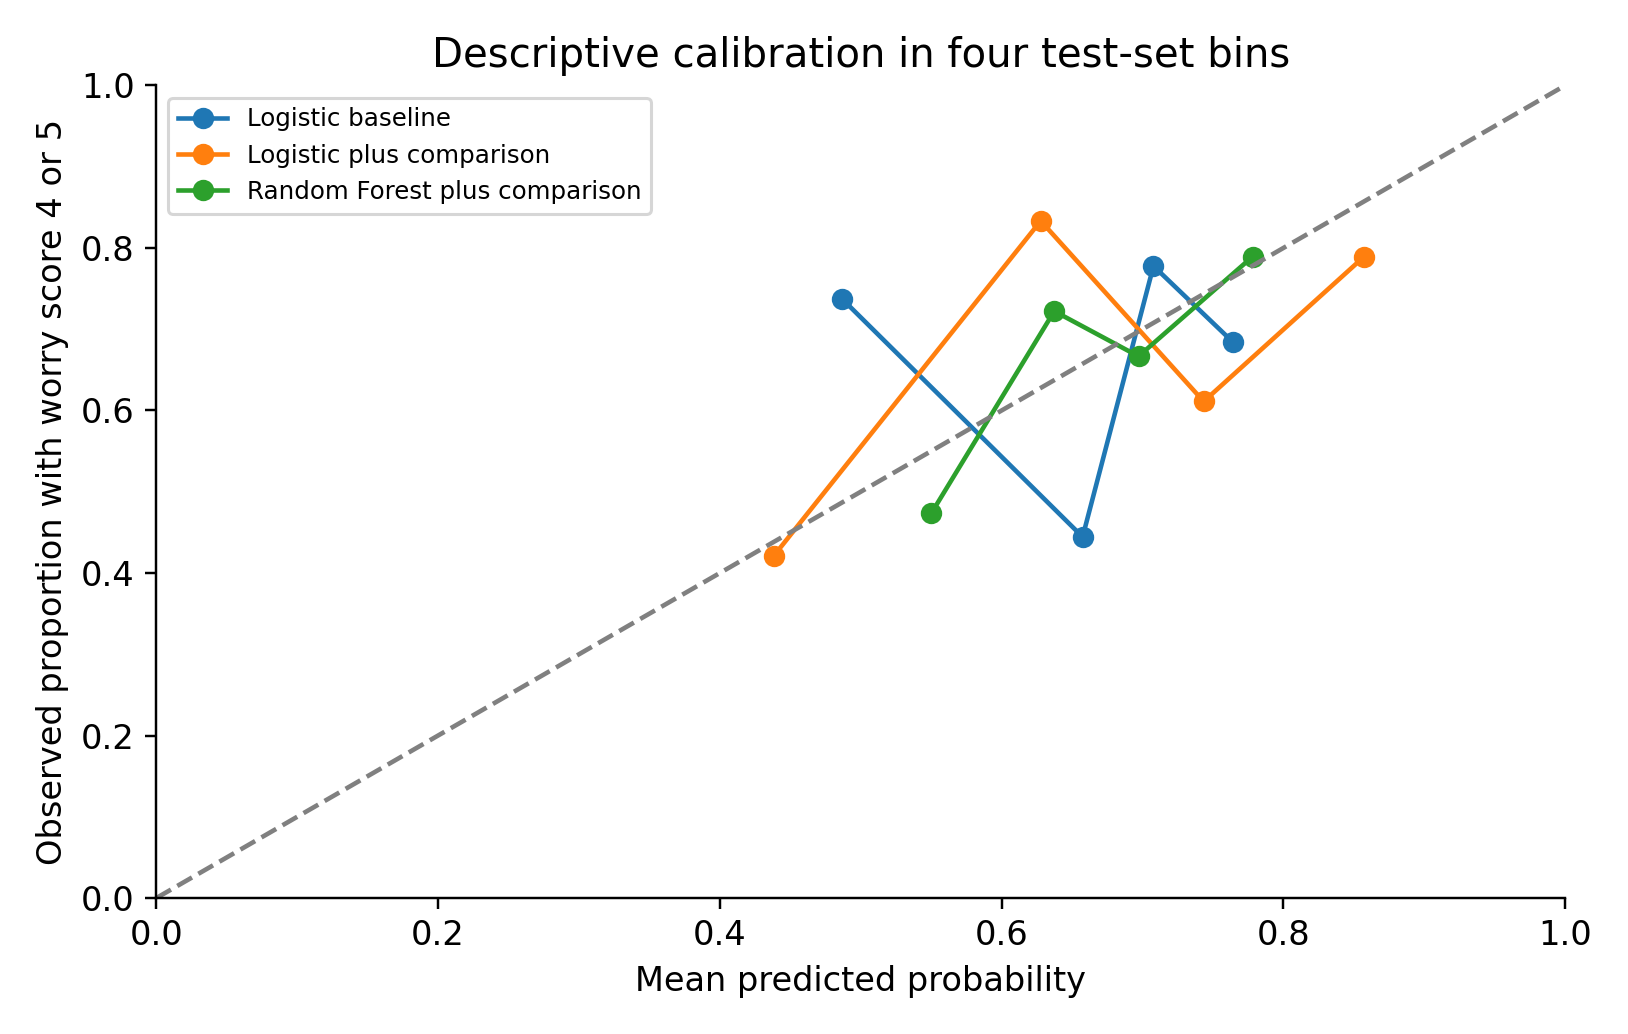

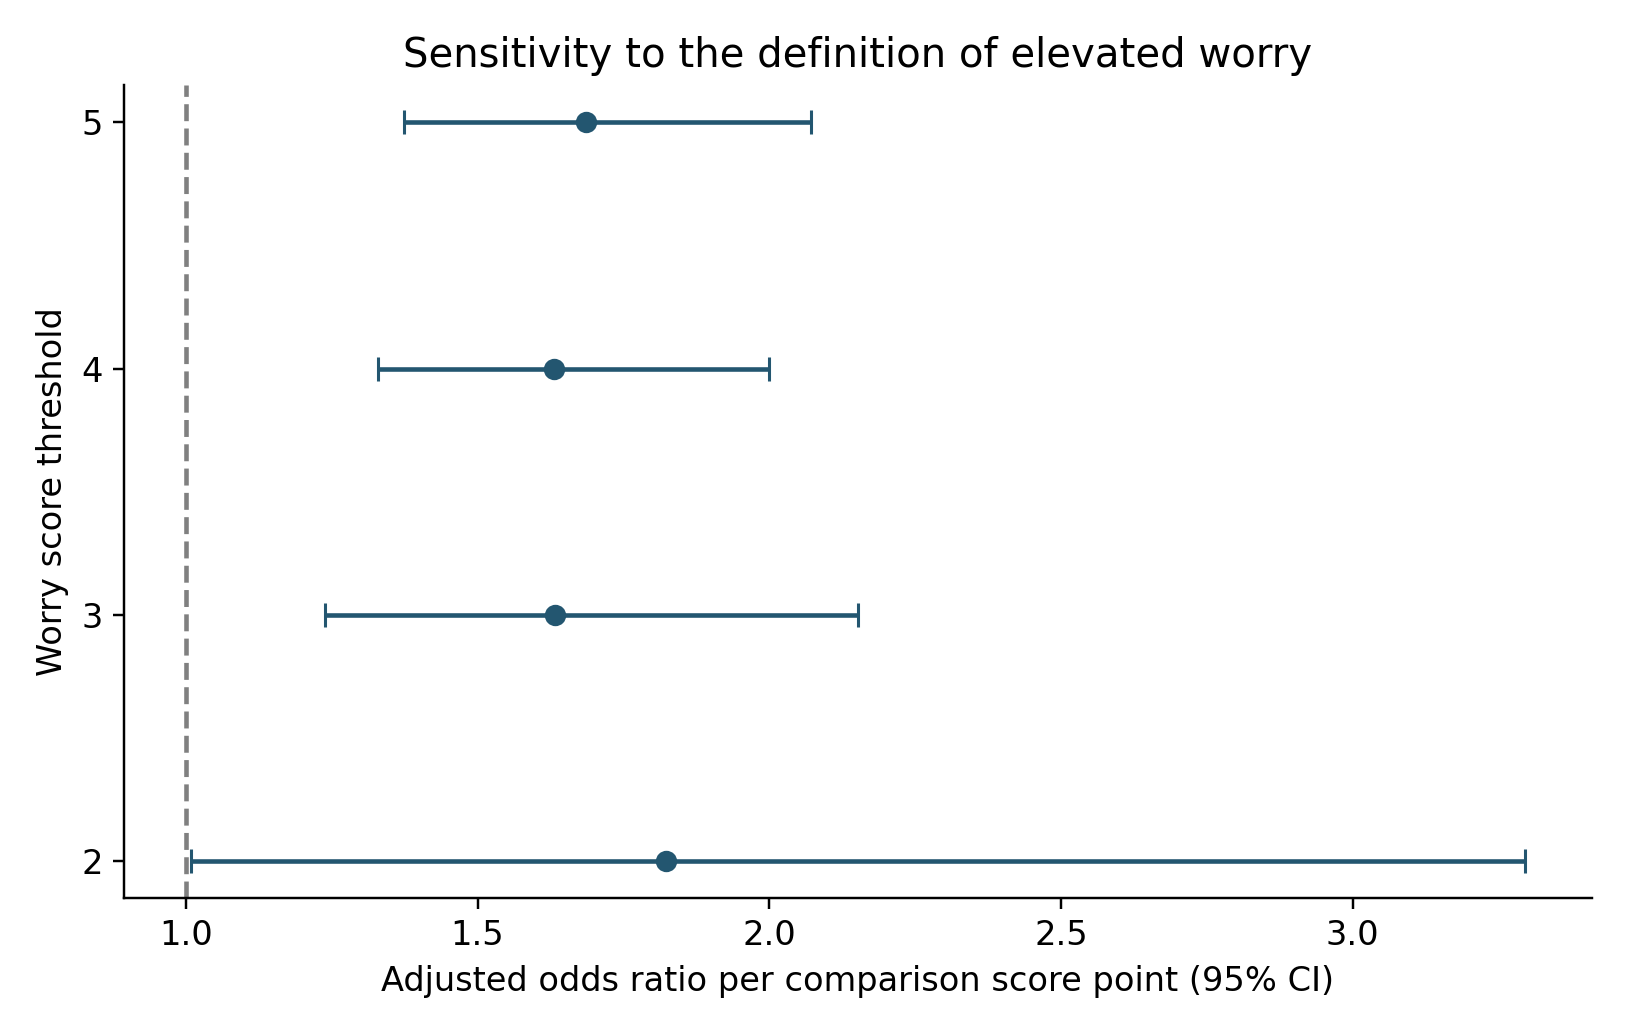

In [9]:
from IPython.display import display, Image
for filename in ["test_metrics.csv","test_bootstrap_intervals.csv","sample_sensitivity.csv","threshold_sensitivity.csv"]:
    print(filename)
    display(pd.read_csv(OUT/filename).round(4))
for filename in ["01_comparison_worry.png", "02_roc.png", "03_calibration.png", "04_threshold_sensitivity.png"]:
    display(Image(filename=str(FIG/filename)))


## Interpretation and code attribution
The report's executed result is a positive comparison–worry association and modest held-out prediction. Original H1–H3 are not tested. Do not select a new random seed to obtain a higher score.

This notebook was prepared with AI assistance for David Dingani. It uses original task-specific analysis code and the public APIs documented by the software authors; it does not copy a source study's analytical results. The researcher should review the code and disclose assistance according to institutional requirements.

References: SouvikAhmed071 (2023), [source dataset](https://www.kaggle.com/datasets/souvikahmed071/social-media-and-mental-health); Kapoor and Narayanan (2023), [leakage and reproducibility](https://doi.org/10.1016/j.patter.2023.100804); Lones (2024), [ML pitfalls](https://doi.org/10.1016/j.patter.2024.101046); [scikit-learn pipeline guidance](https://scikit-learn.org/stable/common_pitfalls.html); [statsmodels OrderedModel](https://www.statsmodels.org/stable/generated/statsmodels.miscmodels.ordinal_model.OrderedModel.html). Full Harvard references are in the report.


## Documented extension
Notebook 04 adds exploratory platform comparisons and a separate TikTok diary analysis. The models, sample split, thresholds and captured empirical results in this notebook remain unchanged; the extension is not a second test set or a basis for retuning these classifiers.